# Dynamic Model in Levels (EmbeddingGemma 2 embeddings)

Re-run of `04_evaluation.ipynb` in which the fine-tuned (DoubleMLDeep) product embeddings are replaced by off-the-shelf embeddings from [EmbeddingGemma 2](https://huggingface.co/google/embeddinggemma-2) (`google/embeddinggemma-2`).

All embedding-derived variables (`emb_*`, `pca_*`, `similarity_cluster_*`) are recomputed from the EmbeddingGemma 2 embeddings (`01_3_compute_embeddings_gemma.ipynb`, `01_4_create_dataset_gemma.ipynb`); all other variables and the estimation sample are identical to the main analysis. Apart from the parameters below, the output directory, and the export of the key results at the end, the notebook is identical to `04_evaluation.ipynb`.

Main specification: text + image embeddings truncated to 256 dimensions (Matryoshka), i.e. the same dimension as the fine-tuned embeddings.

In [1]:
# Embeddings used for emb_*, pca_* and similarity_cluster_*
embedding_source = "embeddinggemma2"  # "embeddinggemma2" | "finetuned" (fine-tuned embeddings, as in 04_evaluation.ipynb)
modality = "txtimg"  # EmbeddingGemma 2 input: "txtimg" (text + image) | "txt" (text only)
emb_dim = 256  # EmbeddingGemma 2 Matryoshka dimension: 768 | 256

In [2]:
import os
import datasets
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from lightgbm import LGBMRegressor
from sklearn.metrics import r2_score

import doubleml as dml

from utils.utils_data2 import (
    get_cis,
    generate_basis,
    generate_interactions,
)

from utils.utils_models import (
    iv_model,
    lin_model,
    lin_model_cate,
    summarize_lin_model,
    summarize_dml,
    chi2_test,
    predict_cate,
)
import warnings
warnings.filterwarnings("ignore")

# Get a colorblind-friendly palette
palette = sns.color_palette("colorblind")

confidence_level = 0.9
ci_level_name, ci_names = get_cis(confidence_level)

run_name = (
    "finetuned"
    if embedding_source == "finetuned"
    else f"embeddinggemma2_{modality}_dim{emb_dim}"
)
output_dir = f"../output/04_evaluation_gemma/{run_name}"
Path(output_dir).mkdir(parents=True, exist_ok=True)

/tmp/claude-0/-home-user-demand-analysis-repro/8871aba3-e06d-5440-87b8-bf4072e29cf1/scratchpad/venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Confidence Level: 90.0%


In [3]:
txt_only = False
include_embeddings = True
if embedding_source == "finetuned":
    dataframe_name = f"dataset_txt_only_{txt_only}_embeddings_{include_embeddings}"
else:
    dataframe_name = f"dataset_gemma_{modality}_dim{emb_dim}"
df_full_train = pd.read_csv(f"../data/{dataframe_name}_train.zip")
df_full_val = pd.read_csv(f"../data/{dataframe_name}_val.zip")

columns_to_drop = [
    "Q_t-2",
    "P_bb_t-2",
    "REVIEW_COUNT_t-2",
    "RATING_t-2",
    "pred_ml_l_lag_1",
    "pred_ml_m_lag_1",
]


df_full_train = df_full_train.drop(columns=columns_to_drop)
df_full_val = df_full_val.drop(columns=columns_to_drop)

df_full_train = df_full_train.dropna()
df_full_val = df_full_val.dropna()

dummy_subcat_names = [
    category for category in df_full_val["subcat_aggregated"].unique()
]
all_time_steps = sorted([str(date) for date in df_full_val["date"].unique()])

print(f"Dummy subcat names: {dummy_subcat_names}")
print(f"All time steps: {all_time_steps}")
df_full_val.columns

Dummy subcat names: ['Residual', 'Cars & Race Cars', 'Trains & Trams', 'Train Sets', 'Trucks', 'Tractors', 'Race Tracks', 'Airplanes', 'Motor Vehicles', 'Vehicle Playsets', 'Skateboards']
All time steps: ['2023-02-27', '2023-03-27', '2023-04-24', '2023-05-22', '2023-06-19', '2023-07-17', '2023-08-14', '2023-09-11', '2023-10-09', '2023-11-06', '2023-12-04', '2024-01-01', '2024-01-29']


Index(['ASIN', 'date', 'index', 'Q_t', 'PRICE', 'P_bb_t', 'text', 'window',
       'REVIEW_COUNT', 'RATING',
       ...
       'REVIEW_COUNT_t-1', 'RATING_t-1', 'Delta_Q_t', 'Delta_P_bb_t',
       'pred_ml_l', 'pred_ml_m', 'pred_ml_l_diff', 'pred_ml_m_diff',
       'pred_ml_l_diff_lag_1', 'pred_ml_m_diff_lag_1'],
      dtype='object', length=342)

In [4]:
print(dataframe_name)

dataset_gemma_txtimg_dim256


In [5]:
print(df_full_val.shape)
print(df_full_train.shape)

(38041, 342)
(38146, 342)


In [6]:
# same estimation sample as in the main analysis (keys written by 04_evaluation.ipynb)
assert df_full_val[["ASIN", "date"]].reset_index(drop=True).equals(pd.read_csv("main_val_keys.csv"))
assert df_full_train[["ASIN", "date"]].reset_index(drop=True).equals(pd.read_csv("main_train_keys.csv"))

In [7]:
df_full_val.isna().sum()

ASIN                    0
date                    0
index                   0
Q_t                     0
PRICE                   0
                       ..
pred_ml_m               0
pred_ml_l_diff          0
pred_ml_m_diff          0
pred_ml_l_diff_lag_1    0
pred_ml_m_diff_lag_1    0
Length: 342, dtype: int64

In [8]:
df_full_train["date"].unique()

array(['2023-02-27', '2023-03-27', '2023-04-24', '2023-05-22',
       '2023-06-19', '2023-07-17', '2023-08-14', '2023-09-11',
       '2023-10-09', '2023-11-06', '2023-12-04', '2024-01-01',
       '2024-01-29'], dtype=object)

In [9]:
df_full_val["date"].unique()

array(['2023-02-27', '2023-03-27', '2023-04-24', '2023-05-22',
       '2023-06-19', '2023-07-17', '2023-08-14', '2023-09-11',
       '2023-10-09', '2023-11-06', '2023-12-04', '2024-01-01',
       '2024-01-29'], dtype=object)

In [10]:
df_full_train["ASIN"].nunique()

3717

In [11]:
df_full_val["ASIN"].nunique()

3708

In [12]:
from datetime import datetime

date_objects = [datetime.strptime(date, "%Y-%m-%d") for date in all_time_steps]

# Calculate the difference in days between consecutive dates
date_differences = [
    (date_objects[i + 1] - date_objects[i]).days for i in range(len(date_objects) - 1)
]

# Print the differences
print(date_differences)

[28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28]


## Variable Names

In [13]:
n_lags = 1

outcome = ["Q_t"]
base_treatment = ["P_bb_t"]
lag_1_vars = ["Q_t-1", "P_bb_t-1"]

dummy_time_steps = all_time_steps[n_lags:]

all_dummy_controls = (
    dummy_subcat_names
    + dummy_time_steps
    + [
        "Lightning Deals: Upcoming Deal",
        "Buy Box: Is FBA",
    ]
)
dummy_baselines = [dummy_time_steps[0], "Residual"]
dummy_time_steps_wo_baseline = [t for t in dummy_time_steps if t not in dummy_baselines]
dummy_controls = [t for t in all_dummy_controls if t not in dummy_baselines]

cont_controls = [
    "RATING_t-1",
    "REVIEW_COUNT_t-1",
    "New Offer Count: Current",
    "Count of retrieved live offers: New, FBA",
    "Count of retrieved live offers: New, FBM",
]

add_controls_to_scale = [
    "RATING",
    "REVIEW_COUNT",
]

controls_pca = ["pca_0", "pca_1", "pca_2", "pca_3", "pca_4"]
controls_similarities = [
    "similarity_cluster_0",
    "similarity_cluster_1",
    "similarity_cluster_2",
    "similarity_cluster_3",
    "similarity_cluster_4",
]

n_embeddings = 256 if embedding_source == "finetuned" else emb_dim
embeddings = [f"emb_{i}" for i in range(n_embeddings)]
assert set(embeddings) == {c for c in df_full_val.columns if c.startswith("emb_")}

controls_to_scale = cont_controls + add_controls_to_scale

additional_controls = cont_controls + dummy_controls

## Interactions & CATE Basis

In [14]:
basis_vars = controls_similarities + lag_1_vars
df_basis, column_transformer, column_dict = generate_basis(
    df=df_full_val,
    cols_without_scaling=controls_similarities,
    cols_to_scale=lag_1_vars,
    degree=1,
)
df_basis.head()

,intercept,Q_t-1,P_bb_t-1,similarity_cluster_0,similarity_cluster_1,similarity_cluster_2,similarity_cluster_3,similarity_cluster_4
0,1.0,0.305280,0.463601,-0.124667,0.032045,0.153362,-0.01167,-0.11198
1,1.0,0.272505,0.653600,-0.124667,0.032045,0.153362,-0.01167,-0.11198
2,1.0,0.036240,0.687961,-0.124667,0.032045,0.153362,-0.01167,-0.11198
3,1.0,0.025283,0.636881,-0.124667,0.032045,0.153362,-0.01167,-0.11198
4,1.0,-0.051370,0.556816,-0.124667,0.032045,0.153362,-0.01167,-0.11198


In [15]:
df_interact_val, interaction_vars = generate_interactions(
    df=df_full_val, df_basis=df_basis, cols_to_interact=["Q_t-1", "P_bb_t-1"]
)

print(f"Interactions: {interaction_vars}")
df_interact_val.columns

Interactions: ['interaction_Q_t-1_intercept', 'interaction_Q_t-1_Q_t-1', 'interaction_Q_t-1_P_bb_t-1', 'interaction_Q_t-1_similarity_cluster_0', 'interaction_Q_t-1_similarity_cluster_1', 'interaction_Q_t-1_similarity_cluster_2', 'interaction_Q_t-1_similarity_cluster_3', 'interaction_Q_t-1_similarity_cluster_4', 'interaction_P_bb_t-1_intercept', 'interaction_P_bb_t-1_Q_t-1', 'interaction_P_bb_t-1_P_bb_t-1', 'interaction_P_bb_t-1_similarity_cluster_0', 'interaction_P_bb_t-1_similarity_cluster_1', 'interaction_P_bb_t-1_similarity_cluster_2', 'interaction_P_bb_t-1_similarity_cluster_3', 'interaction_P_bb_t-1_similarity_cluster_4']


Index(['ASIN', 'date', 'index', 'Q_t', 'PRICE', 'P_bb_t', 'text', 'window',
       'REVIEW_COUNT', 'RATING',
       ...
       'interaction_Q_t-1_similarity_cluster_3',
       'interaction_Q_t-1_similarity_cluster_4',
       'interaction_P_bb_t-1_intercept', 'interaction_P_bb_t-1_Q_t-1',
       'interaction_P_bb_t-1_P_bb_t-1',
       'interaction_P_bb_t-1_similarity_cluster_0',
       'interaction_P_bb_t-1_similarity_cluster_1',
       'interaction_P_bb_t-1_similarity_cluster_2',
       'interaction_P_bb_t-1_similarity_cluster_3',
       'interaction_P_bb_t-1_similarity_cluster_4'],
      dtype='object', length=358)

## Average Effect

In [16]:
df_dynamic = df_interact_val.copy()

### Linear Models

In [17]:
def estimate_linear_model(controls):
    model = lin_model(
        df=df_dynamic,
        outcome=outcome,
        treatments=base_treatment,
        controls=controls,
        level=confidence_level,
        cov_type="cluster",
        cov_kwds={"groups": df_dynamic["ASIN"]},
    )
    return model

In [18]:
estimate_linear_model(controls=[])

Adjusted R^2: 0.0027
          coef  std err        t  P>|t|   [5.0%  95.0%]
const  -10.756    0.104 -103.858  0.000 -10.926 -10.586
P_bb_t  -0.111    0.033   -3.384  0.001  -0.164  -0.057


,lower,upper,coef
P_bb_t,-0.164462,-0.056884,-0.110673


In [19]:
estimate_linear_model(controls=embeddings)

Adjusted R^2: 0.3983
          coef  std err       t  P>|t|   [5.0%  95.0%]
const   -9.919    0.119 -83.598  0.000 -10.114  -9.724
P_bb_t  -0.401    0.039 -10.381  0.000  -0.464  -0.337
emb_0    1.068    0.499   2.142  0.032   0.248   1.889
emb_1    1.742    0.493   3.534  0.000   0.931   2.552
emb_2    0.736    0.520   1.416  0.157  -0.119   1.591
...        ...      ...     ...    ...     ...     ...
emb_251  0.685    0.444   1.543  0.123  -0.045   1.415
emb_252 -1.116    0.554  -2.012  0.044  -2.028  -0.204
emb_253 -0.637    0.460  -1.386  0.166  -1.393   0.119
emb_254  0.004    0.512   0.008  0.993  -0.837   0.846
emb_255 -1.334    0.539  -2.476  0.013  -2.221  -0.448

[258 rows x 6 columns]


,lower,upper,coef
P_bb_t,-0.464083,-0.33713,-0.400606


In [20]:
estimate_linear_model(controls=additional_controls)

Adjusted R^2: 0.2213
                                            coef  std err       t  P>|t|  \
const                                    -11.961    0.233 -51.298  0.000   
P_bb_t                                    -0.225    0.031  -7.254  0.000   
RATING_t-1                                 0.222    0.047   4.710  0.000   
REVIEW_COUNT_t-1                           0.000    0.000   5.015  0.000   
New Offer Count: Current                  -0.015    0.006  -2.599  0.009   
Count of retrieved live offers: New, FBA   0.056    0.013   4.217  0.000   
Count of retrieved live offers: New, FBM  -0.033    0.008  -4.285  0.000   
Cars & Race Cars                           0.259    0.057   4.513  0.000   
Trains & Trams                             0.456    0.131   3.473  0.001   
Train Sets                                 0.422    0.077   5.454  0.000   
Trucks                                     0.464    0.064   7.291  0.000   
Tractors                                   0.399    0.131   3.042  

,lower,upper,coef
P_bb_t,-0.275748,-0.173807,-0.224778


In [21]:
estimate_linear_model(controls=additional_controls + embeddings)

Adjusted R^2: 0.487
                            coef  std err       t  P>|t|   [5.0%  95.0%]
const                    -11.209    0.202 -55.419  0.000 -11.542 -10.877
P_bb_t                    -0.376    0.035 -10.672  0.000  -0.434  -0.318
RATING_t-1                 0.203    0.036   5.580  0.000   0.143   0.263
REVIEW_COUNT_t-1           0.000    0.000   5.488  0.000   0.000   0.000
New Offer Count: Current  -0.005    0.005  -1.111  0.267  -0.013   0.003
...                          ...      ...     ...    ...     ...     ...
emb_251                    0.520    0.398   1.309  0.190  -0.133   1.174
emb_252                   -1.210    0.492  -2.458  0.014  -2.020  -0.400
emb_253                   -0.732    0.413  -1.771  0.077  -1.412  -0.052
emb_254                    0.247    0.459   0.538  0.590  -0.508   1.002
emb_255                   -0.793    0.482  -1.644  0.100  -1.586   0.000

[286 rows x 6 columns]


,lower,upper,coef
P_bb_t,-0.434058,-0.318125,-0.376092


In [22]:
ci_linear_base_lagged = estimate_linear_model(controls=lag_1_vars)

Adjusted R^2: 0.8835
           coef  std err        t  P>|t|  [5.0%  95.0%]
const    -0.677    0.034  -19.935    0.0 -0.733  -0.621
P_bb_t   -0.690    0.040  -17.248    0.0 -0.756  -0.624
Q_t-1     0.936    0.003  321.411    0.0  0.931   0.941
P_bb_t-1  0.678    0.040   16.995    0.0  0.613   0.744


In [23]:
ci_linear_embeddings = estimate_linear_model(controls=lag_1_vars + embeddings)

Adjusted R^2: 0.8864
           coef  std err        t  P>|t|  [5.0%  95.0%]
const    -1.038    0.047  -22.203  0.000 -1.115  -0.961
P_bb_t   -0.681    0.040  -17.167  0.000 -0.746  -0.616
Q_t-1     0.893    0.004  205.780  0.000  0.886   0.900
P_bb_t-1  0.629    0.039   15.930  0.000  0.564   0.694
emb_0     0.167    0.069    2.411  0.016  0.053   0.281
...         ...      ...      ...    ...    ...     ...
emb_251   0.088    0.061    1.441  0.150 -0.012   0.188
emb_252  -0.156    0.077   -2.033  0.042 -0.283  -0.030
emb_253   0.029    0.062    0.467  0.640 -0.073   0.131
emb_254   0.005    0.070    0.069  0.945 -0.110   0.120
emb_255  -0.077    0.075   -1.035  0.301 -0.200   0.046

[260 rows x 6 columns]


In [24]:
ci_linear_base_lagged_add_controls = estimate_linear_model(
    controls=lag_1_vars + additional_controls
)

Adjusted R^2: 0.8929
                                           coef  std err        t  P>|t|  \
const                                    -0.962    0.051  -18.978  0.000   
P_bb_t                                   -0.746    0.039  -18.956  0.000   
Q_t-1                                     0.925    0.003  279.493  0.000   
P_bb_t-1                                  0.722    0.039   18.383  0.000   
RATING_t-1                                0.030    0.007    4.621  0.000   
REVIEW_COUNT_t-1                          0.000    0.000    8.670  0.000   
New Offer Count: Current                 -0.001    0.001   -1.625  0.104   
Count of retrieved live offers: New, FBA  0.005    0.001    3.398  0.001   
Count of retrieved live offers: New, FBM -0.004    0.001   -3.797  0.000   
Cars & Race Cars                          0.020    0.006    3.371  0.001   
Trains & Trams                            0.052    0.014    3.754  0.000   
Train Sets                                0.032    0.008    4.069  

In [25]:
ci_linear_base_lagged_add_controls_emb = estimate_linear_model(
    controls=lag_1_vars + additional_controls + embeddings
)

Adjusted R^2: 0.8952
             coef  std err        t  P>|t|  [5.0%  95.0%]
const      -1.336    0.065  -20.670  0.000 -1.443  -1.230
P_bb_t     -0.731    0.039  -18.734  0.000 -0.795  -0.667
Q_t-1       0.887    0.005  187.135  0.000  0.879   0.895
P_bb_t-1    0.679    0.039   17.444  0.000  0.615   0.743
RATING_t-1  0.037    0.008    4.741  0.000  0.024   0.050
...           ...      ...      ...    ...    ...     ...
emb_251     0.077    0.060    1.283  0.200 -0.022   0.177
emb_252    -0.178    0.074   -2.402  0.016 -0.299  -0.056
emb_253     0.024    0.061    0.394  0.693 -0.077   0.125
emb_254     0.029    0.069    0.422  0.673 -0.084   0.143
emb_255    -0.047    0.073   -0.635  0.525 -0.167   0.074

[288 rows x 6 columns]


In [26]:
ci_linear_base_lagged_add_controls_sim = estimate_linear_model(
    controls=lag_1_vars + controls_similarities + additional_controls
)

Adjusted R^2: 0.8935
                                           coef  std err        t  P>|t|  \
const                                    -1.092    0.056  -19.664  0.000   
P_bb_t                                   -0.735    0.039  -18.758  0.000   
Q_t-1                                     0.915    0.004  244.957  0.000   
P_bb_t-1                                  0.709    0.039   18.122  0.000   
similarity_cluster_0                      1.498    0.137   10.935  0.000   
similarity_cluster_1                      1.961    0.194   10.131  0.000   
similarity_cluster_2                      1.426    0.152    9.398  0.000   
similarity_cluster_3                      1.637    0.163   10.071  0.000   
similarity_cluster_4                      1.352    0.138    9.795  0.000   
RATING_t-1                                0.035    0.007    5.099  0.000   
REVIEW_COUNT_t-1                          0.000    0.000    9.046  0.000   
New Offer Count: Current                 -0.001    0.001   -1.919  

In [27]:
ci_linear_interactions = estimate_linear_model(
    controls=interaction_vars + controls_similarities + additional_controls
)

Adjusted R^2: 0.8938
                                            coef  std err       t  P>|t|  \
const                                     -1.555    0.346  -4.494  0.000   
P_bb_t                                    -0.736    0.039 -18.706  0.000   
interaction_Q_t-1_intercept                0.636    0.031  20.596  0.000   
interaction_Q_t-1_Q_t-1                   -0.010    0.004  -2.641  0.008   
interaction_Q_t-1_P_bb_t-1                -0.049    0.002 -23.181  0.000   
interaction_Q_t-1_similarity_cluster_0     0.289    0.161   1.790  0.073   
interaction_Q_t-1_similarity_cluster_1     0.422    0.234   1.798  0.072   
interaction_Q_t-1_similarity_cluster_2     0.291    0.175   1.667  0.096   
interaction_Q_t-1_similarity_cluster_3     0.364    0.205   1.781  0.075   
interaction_Q_t-1_similarity_cluster_4     0.301    0.174   1.733  0.083   
interaction_P_bb_t-1_intercept            -0.161    0.009 -18.070  0.000   
interaction_P_bb_t-1_Q_t-1                 0.088    0.009   9.793  

In [28]:
ci_linear_base_lagged["model"] = "Linear lagged"
ci_linear_embeddings["model"] = "Linear lagged_and_embeddings"
ci_linear_base_lagged_add_controls["model"] = "Linear lagged_and_add_controls"
ci_linear_base_lagged_add_controls_emb["model"] = (
    "Linear lagged_and_add_controls_and_emb"
)
ci_linear_base_lagged_add_controls_sim["model"] = (
    "Linear lagged_and_add_controls_and_sim"
)
ci_linear_interactions["model"] = "Linear interactions"

df_base = pd.concat(
    [
        ci_linear_base_lagged,
        ci_linear_embeddings,
        ci_linear_base_lagged_add_controls,
        ci_linear_base_lagged_add_controls_emb,
        ci_linear_base_lagged_add_controls_sim,
    ],
    ignore_index=True,
)

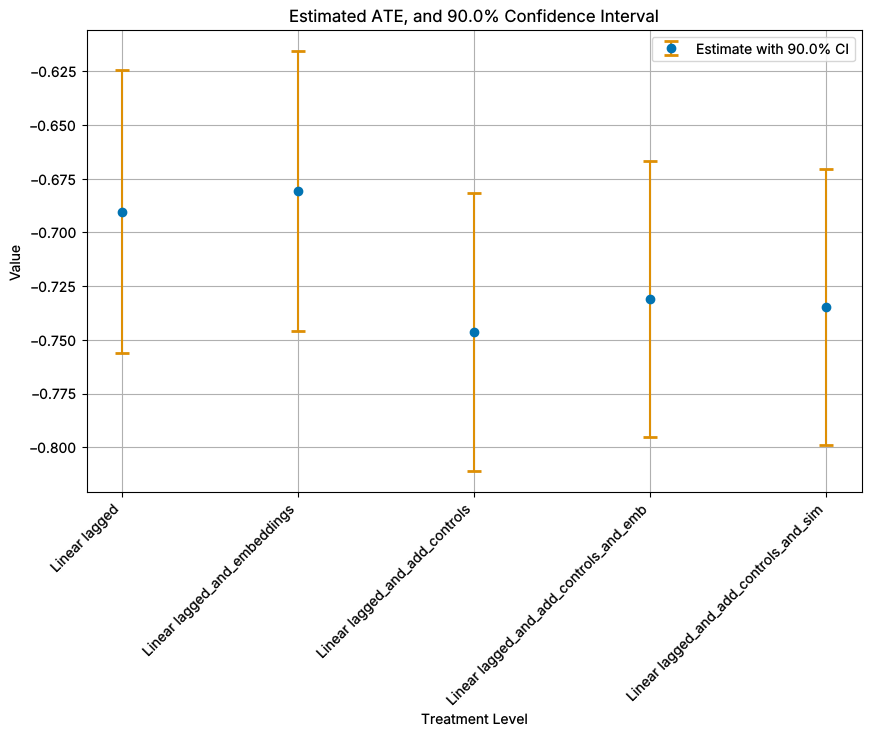

In [29]:
# Plotting
plt.figure(figsize=(10, 6))
# Plot Estimate with CI
plt.errorbar(
    df_base["model"],
    df_base["coef"],
    yerr=[df_base["coef"] - df_base["lower"], df_base["upper"] - df_base["coef"]],
    fmt="o",
    capsize=5,
    capthick=2,
    ecolor=palette[1],
    color=palette[0],
    label=f"Estimate with {round(confidence_level * 100, 1)}% CI",
    zorder=2,
)

plt.title(f"Estimated ATE, and {round(confidence_level * 100, 1)}% Confidence Interval")
plt.xlabel("Treatment Level")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Value")
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(output_dir, f"linear_ate_estimates.png"))
plt.show()

In [30]:
df_base

,lower,upper,coef,model
0,-0.756093,-0.624438,-0.690266,Linear lagged
1,-0.746076,-0.615608,-0.680842,Linear lagged_and_embeddings
2,-0.811127,-0.681600,-0.746364,Linear lagged_and_add_controls
3,-0.795353,-0.666959,-0.731156,Linear lagged_and_add_controls_and_emb
4,-0.799087,-0.670245,-0.734666,Linear lagged_and_add_controls_and_sim


### DML Models

In [31]:
ml_g = LGBMRegressor(n_estimators=500, lr=0.02, random_state=42, verbose=-1)
ml_m = LGBMRegressor(n_estimators=500, lr=0.02, random_state=42, verbose=-1)


def r2(y_true, y_pred):
    subset = np.logical_not(np.isnan(y_true))
    return r2_score(y_true[subset], y_pred[subset])


def estimate_dml_model(controls):
    tab_dml_data = dml.DoubleMLClusterData(
        df_dynamic,
        y_col=outcome[0],
        d_cols=base_treatment,
        x_cols=controls,
        cluster_cols="ASIN",
    )

    np.random.seed(3141)
    tab_dml_obj = dml.DoubleMLPLR(tab_dml_data, ml_g, ml_m)
    tab_dml_obj.fit()

    tab_summary_df = summarize_dml(tab_dml_obj, level=confidence_level)
    ci_tab_dml = tab_summary_df[ci_names + ["coef"]]
    ci_tab_dml.columns = ["lower", "upper", "coef"]

    r2_scores = tab_dml_obj.evaluate_learners(metric=r2)
    print(
        f"R2 Outcome: {round(r2_scores['ml_l'][0, 0], 4)} R2 Treatment: {round(r2_scores['ml_m'][0, 0], 4)}\n"
    )

    return tab_dml_obj, ci_tab_dml

In [32]:
tab_dml_obj_embeddings, ci_tab_dml_embeddings = estimate_dml_model(
    controls=lag_1_vars + embeddings
)

         coef  std err       t  P>|t|   5.0%  95.0%
P_bb_t -0.652    0.044 -14.848    0.0 -0.725  -0.58
R2 Outcome: 0.8692 R2 Treatment: 0.9746



In [33]:
tab_dml_obj_add_controls, ci_tab_dml_add_controls = estimate_dml_model(
    controls=lag_1_vars + additional_controls
)

        coef  std err       t  P>|t|   5.0%  95.0%
P_bb_t -0.69    0.041 -16.812    0.0 -0.758 -0.623
R2 Outcome: 0.8991 R2 Treatment: 0.9775



In [34]:
tab_dml_obj_embeddings_add_controls, ci_tab_dml_embeddings_add_controls = (
    estimate_dml_model(controls=lag_1_vars + embeddings + additional_controls)
)

         coef  std err       t  P>|t|   5.0%  95.0%
P_bb_t -0.701    0.046 -15.225    0.0 -0.776 -0.625
R2 Outcome: 0.8953 R2 Treatment: 0.9762



In [35]:
tab_dml_obj_sim_add_controls, ci_tab_dml_sim_add_controls = estimate_dml_model(
    controls=lag_1_vars + controls_similarities + additional_controls
)

         coef  std err       t  P>|t|   5.0%  95.0%
P_bb_t -0.684    0.039 -17.396    0.0 -0.749  -0.62
R2 Outcome: 0.8998 R2 Treatment: 0.977



In [36]:
tab_dml_obj_pca_add_controls, ci_tab_dml_pca_add_controls = estimate_dml_model(
    controls=lag_1_vars + controls_pca + additional_controls
)

         coef  std err       t  P>|t|   5.0%  95.0%
P_bb_t -0.689    0.041 -16.859    0.0 -0.757 -0.622
R2 Outcome: 0.8995 R2 Treatment: 0.977



### Visualization

In [37]:
ci_tab_dml_embeddings["model"] = "plr_embeddings"
ci_tab_dml_add_controls["model"] = "plr_add_controls"
ci_tab_dml_embeddings_add_controls["model"] = "plr_embeddings_add_controls"
ci_tab_dml_sim_add_controls["model"] = "plr_sim_add_controls"
ci_tab_dml_pca_add_controls["model"] = "plr_pca_add_controls"


df_averages = pd.concat(
    [
        ci_tab_dml_embeddings,
        ci_tab_dml_add_controls,
        ci_tab_dml_embeddings_add_controls,
        ci_tab_dml_sim_add_controls,
        ci_tab_dml_pca_add_controls,
    ],
    ignore_index=True,
)

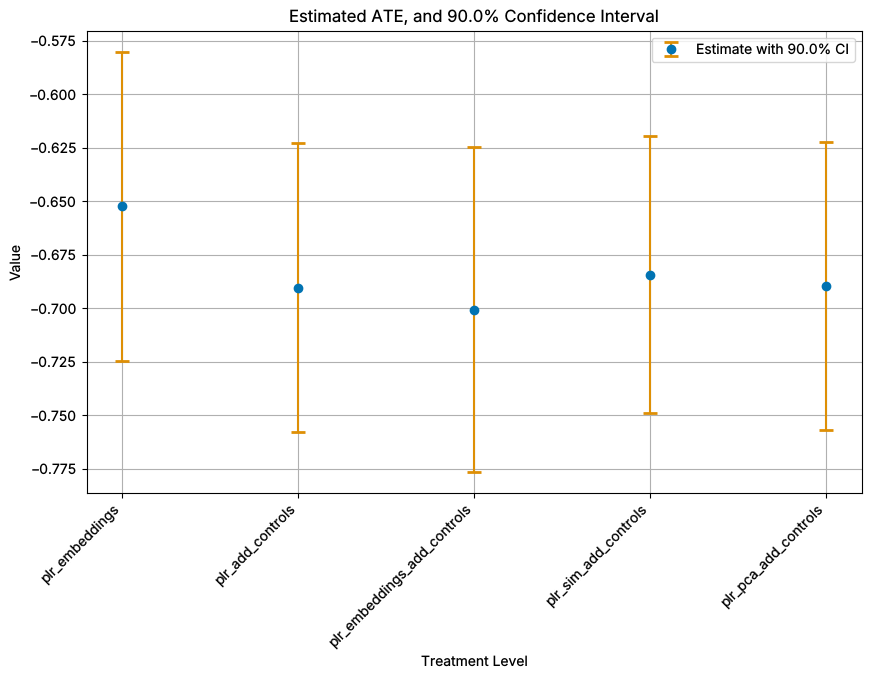

In [38]:
# Plotting
plt.figure(figsize=(10, 6))
# Plot Estimate with CI
plt.errorbar(
    df_averages["model"],
    df_averages["coef"],
    yerr=[
        df_averages["coef"] - df_averages["lower"],
        df_averages["upper"] - df_averages["coef"],
    ],
    fmt="o",
    capsize=5,
    capthick=2,
    ecolor=palette[1],
    color=palette[0],
    label=f"Estimate with {round(confidence_level * 100, 1)}% CI",
    zorder=2,
)

plt.title(f"Estimated ATE, and {round(confidence_level * 100, 1)}% Confidence Interval")
plt.xlabel("Treatment Level")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Value")
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(output_dir, f"plr_ate_estimates.png"))
plt.show()

## GATEs

0
similarity_cluster_0     8199
similarity_cluster_1    10815
similarity_cluster_2     4167
similarity_cluster_3     8920
similarity_cluster_4     5940
dtype: int64


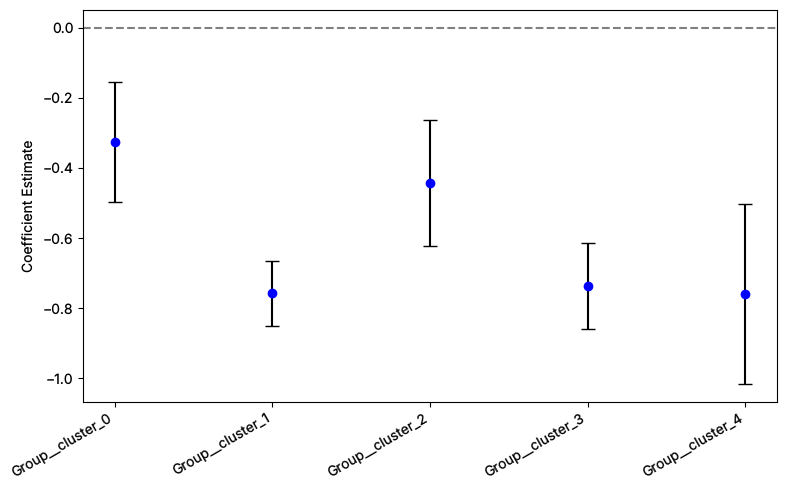

In [39]:
groups = pd.DataFrame(
    df_dynamic[
        [
            "similarity_cluster_0",
            "similarity_cluster_1",
            "similarity_cluster_2",
            "similarity_cluster_3",
            "similarity_cluster_4",
        ]
    ].idxmax(axis=1)
)

print(groups.groupby(0).size())
gates_0 = tab_dml_obj_embeddings.gate(groups)
gates_0_summ = gates_0.summary
gates_0_summ["err_lower"] = gates_0_summ["coef"] - gates_0_summ["[0.025"]
gates_0_summ["err_upper"] = gates_0_summ["0.975]"] - gates_0_summ["coef"]

# Positions on the x-axis
x_vals = range(len(gates_0_summ))

plt.figure(figsize=(8, 5))
plt.errorbar(
    x=x_vals,
    y=gates_0_summ["coef"],
    yerr=[gates_0_summ["err_lower"], gates_0_summ["err_upper"]],
    fmt="o",
    capsize=5,
    color="blue",
    ecolor="black",
)

# Draw a zero line for reference
plt.axhline(y=0, color="gray", linestyle="--")

# Customizing x-axis labels
plt.xticks(
    ticks=x_vals,
    labels=[gr.replace("similarity", "") for gr in gates_0_summ.index],
    rotation=30,
    ha="right",
)
plt.ylabel("Coefficient Estimate")
plt.tight_layout()
plt.show()

## CATEs

In [40]:
uniform_ci = True  # False | True

In [41]:
cate_controls = lag_1_vars + embeddings + additional_controls
cate_controls_interactions = cate_controls + interaction_vars

plr_obj = tab_dml_obj_embeddings_add_controls

In [42]:
import gc

gc.collect()

3123

In [43]:
cate_kwargs_val = {"cov_type": "cluster", "cov_kwds": {"groups": df_dynamic["ASIN"]}}

cate_models_polynomial = {
    "Linear Specification": None,
    "Linear Specification (Interactions)": None,
    "PLR Specification": None,
}

# Linear Models
cate_models_polynomial["Linear Specification"] = lin_model_cate(
    df=df_dynamic,
    outcome=outcome,
    basis=df_basis,
    treatment=base_treatment,
    controls=cate_controls,
    **cate_kwargs_val,
)

print(f"\nLinear Specification")
df_specification_1 = summarize_lin_model(
    cate_models_polynomial["Linear Specification"], level=confidence_level
)
print("=" * 80)  #

cate_models_polynomial["Linear Specification (Interactions)"] = lin_model_cate(
    df=df_dynamic,
    outcome=outcome,
    basis=df_basis,
    treatment=base_treatment,
    controls=cate_controls_interactions,
    **cate_kwargs_val,
)

print(f"\nLinear specification with interactions")
df_specification_2 = summarize_lin_model(
    cate_models_polynomial["Linear Specification (Interactions)"],
    level=confidence_level,
)
print("=" * 80)

# tabular DML model
cate_models_polynomial["PLR Specification"] = plr_obj.cate(df_basis, **cate_kwargs_val)

print(f"\nTabular DML PLR Specification")
df_specification_3 = summarize_lin_model(
    cate_models_polynomial["PLR Specification"].blp_model, level=confidence_level
)
print("=" * 80)


Linear Specification
                       coef  std err       t  P>|t|    5.0%  95.0%
intercept            -0.711    0.041 -17.507  0.000  -0.778 -0.644
Q_t-1                -0.183    0.044  -4.159  0.000  -0.255 -0.111
P_bb_t-1             -0.024    0.036  -0.656  0.512  -0.083  0.036
similarity_cluster_0 -3.841    1.718  -2.236  0.025  -6.667 -1.016
similarity_cluster_1 -6.238    2.532  -2.464  0.014 -10.402 -2.073
similarity_cluster_2 -4.330    1.947  -2.224  0.026  -7.533 -1.128
similarity_cluster_3 -5.412    2.269  -2.385  0.017  -9.144 -1.679
similarity_cluster_4 -4.706    1.942  -2.423  0.015  -7.900 -1.512



Linear specification with interactions
                       coef  std err       t  P>|t|    5.0%  95.0%
intercept            -0.718    0.041 -17.666  0.000  -0.785 -0.651
Q_t-1                -0.190    0.044  -4.351  0.000  -0.261 -0.118
P_bb_t-1             -0.029    0.037  -0.787  0.431  -0.089  0.032
similarity_cluster_0 -3.924    1.726  -2.274  0.023  -6.763 -1.086
similarity_cluster_1 -6.408    2.543  -2.519  0.012 -10.591 -2.224
similarity_cluster_2 -4.462    1.956  -2.280  0.023  -7.680 -1.244
similarity_cluster_3 -5.583    2.278  -2.451  0.014  -9.330 -1.836
similarity_cluster_4 -4.907    1.952  -2.514  0.012  -8.118 -1.697

Tabular DML PLR Specification
                       coef  std err       t  P>|t|   5.0%  95.0%
intercept            -0.693    0.045 -15.524  0.000 -0.767 -0.620
Q_t-1                -0.285    0.077  -3.705  0.000 -0.412 -0.159
P_bb_t-1              0.009    0.029   0.306  0.760 -0.039  0.057
similarity_cluster_0  0.555    2.120   0.262  0.793 -2.931  4.

In [44]:
cate_models_polynomial["Linear Specification (Interactions)"].summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                      y   R-squared (uncentered):                   0.026
Model:                            OLS   Adj. R-squared (uncentered):              0.026
Method:                 Least Squares   F-statistic:                              60.83
Date:                Wed, 14 Oct 2026   Prob (F-statistic):                    8.60e-94
Time:                        02:21:31   Log-Likelihood:                         -21305.
No. Observations:               38041   AIC:                                  4.263e+04
Df Residuals:                   38033   BIC:                                  4.269e+04
Df Model:                           8                                                  
Covariance Type:              cluster                                                  
========================================================================================
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
intercept               -0.7181      0.041    -17.666      0.000      -0.798      -0.638
Q_t-1                   -0.1897      0.044     -4.351      0.000      -0.275      -0.104
P_bb_t-1                -0.0290      0.037     -0.787      0.431      -0.101       0.043
similarity_cluster_0    -3.9244      1.726     -2.274      0.023      -7.307      -0.542
similarity_cluster_1    -6.4076      2.543     -2.519      0.012     -11.393      -1.423
similarity_cluster_2    -4.4617      1.956     -2.280      0.023      -8.296      -0.627
similarity_cluster_3    -5.5827      2.278     -2.451      0.014     -10.048      -1.118
similarity_cluster_4    -4.9073      1.952     -2.514      0.012      -8.733      -1.082
==============================================================================
Omnibus:                    12177.043   Durbin-Watson:                   2.013
Prob(Omnibus):                  0.000   Jarque-Bera (JB):           731248.537
Skew:                           0.719   Prob(JB):                         0.00
Kurtosis:                      24.431   Cond. No.                         148.
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors are robust to cluster correlation (cluster)
"""

In [45]:
cate_models_polynomial["PLR Specification"].blp_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                      y   R-squared (uncentered):                   0.031
Model:                            OLS   Adj. R-squared (uncentered):              0.031
Method:                 Least Squares   F-statistic:                              44.56
Date:                Wed, 14 Oct 2026   Prob (F-statistic):                    9.00e-69
Time:                        02:21:31   Log-Likelihood:                         -20947.
No. Observations:               38041   AIC:                                  4.191e+04
Df Residuals:                   38033   BIC:                                  4.198e+04
Df Model:                           8                                                  
Covariance Type:              cluster                                                  
========================================================================================
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
intercept               -0.6933      0.045    -15.524      0.000      -0.781      -0.606
Q_t-1                   -0.2852      0.077     -3.705      0.000      -0.436      -0.134
P_bb_t-1                 0.0089      0.029      0.306      0.760      -0.048       0.066
similarity_cluster_0     0.5551      2.120      0.262      0.793      -3.599       4.709
similarity_cluster_1     0.1733      3.016      0.057      0.954      -5.738       6.085
similarity_cluster_2     0.5860      2.300      0.255      0.799      -3.922       5.094
similarity_cluster_3     0.0810      2.660      0.030      0.976      -5.133       5.295
similarity_cluster_4     0.1737      2.246      0.077      0.938      -4.229       4.576
==============================================================================
Omnibus:                    14579.827   Durbin-Watson:                   1.605
Prob(Omnibus):                  0.000   Jarque-Bera (JB):           455365.312
Skew:                           1.220   Prob(JB):                         0.00
Kurtosis:                      19.773   Cond. No.                         244.
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors are robust to cluster correlation (cluster)
"""

In [46]:
latex_args = {
    "index": True,
    "float_format": "%.3f",
    "column_format": "lcccccc",
}

print(df_specification_1.to_latex(**latex_args))
print(df_specification_2.to_latex(**latex_args))
print(df_specification_3.to_latex(**latex_args))

\begin{tabular}{lcccccc}
\toprule
 & coef & std err & t & P>|t| & 5.0% & 95.0% \\
\midrule
intercept & -0.711 & 0.041 & -17.507 & 0.000 & -0.778 & -0.644 \\
Q_t-1 & -0.183 & 0.044 & -4.159 & 0.000 & -0.255 & -0.111 \\
P_bb_t-1 & -0.024 & 0.036 & -0.656 & 0.512 & -0.083 & 0.036 \\
similarity_cluster_0 & -3.841 & 1.718 & -2.236 & 0.025 & -6.667 & -1.016 \\
similarity_cluster_1 & -6.238 & 2.532 & -2.464 & 0.014 & -10.402 & -2.073 \\
similarity_cluster_2 & -4.330 & 1.947 & -2.224 & 0.026 & -7.533 & -1.128 \\
similarity_cluster_3 & -5.412 & 2.269 & -2.385 & 0.017 & -9.144 & -1.679 \\
similarity_cluster_4 & -4.706 & 1.942 & -2.423 & 0.015 & -7.900 & -1.512 \\
\bottomrule
\end{tabular}

\begin{tabular}{lcccccc}
\toprule
 & coef & std err & t & P>|t| & 5.0% & 95.0% \\
\midrule
intercept & -0.718 & 0.041 & -17.666 & 0.000 & -0.785 & -0.651 \\
Q_t-1 & -0.190 & 0.044 & -4.351 & 0.000 & -0.261 & -0.118 \\
P_bb_t-1 & -0.029 & 0.037 & -0.787 & 0.431 & -0.089 & 0.032 \\
similarity_cluster_0 & -3.924 

In [47]:
summary_list = []
for model_name, model in cate_models_polynomial.items():
    if "Linear" in model_name:
        tmp_summary = summarize_lin_model(model, level=confidence_level)
    else:
        tmp_summary = summarize_lin_model(model.blp_model, level=confidence_level)
    for index, row in tmp_summary.iterrows():
        variable = index
        summary_list.append(
            {
                "model": model_name,
                "variable": variable,
                "coef": row["coef"],
                "Std.Err.": row["std err"],
                "lower": row[ci_names[0]],  # Adjusted to match the column name
                "upper": row[ci_names[1]],  # Adjusted to match the column name
            }
        )

cate_summary_df = pd.DataFrame(summary_list)

                       coef  std err       t  P>|t|    5.0%  95.0%
intercept            -0.711    0.041 -17.507  0.000  -0.778 -0.644
Q_t-1                -0.183    0.044  -4.159  0.000  -0.255 -0.111
P_bb_t-1             -0.024    0.036  -0.656  0.512  -0.083  0.036
similarity_cluster_0 -3.841    1.718  -2.236  0.025  -6.667 -1.016
similarity_cluster_1 -6.238    2.532  -2.464  0.014 -10.402 -2.073
similarity_cluster_2 -4.330    1.947  -2.224  0.026  -7.533 -1.128
similarity_cluster_3 -5.412    2.269  -2.385  0.017  -9.144 -1.679
similarity_cluster_4 -4.706    1.942  -2.423  0.015  -7.900 -1.512
                       coef  std err       t  P>|t|    5.0%  95.0%
intercept            -0.718    0.041 -17.666  0.000  -0.785 -0.651
Q_t-1                -0.190    0.044  -4.351  0.000  -0.261 -0.118
P_bb_t-1             -0.029    0.037  -0.787  0.431  -0.089  0.032
similarity_cluster_0 -3.924    1.726  -2.274  0.023  -6.763 -1.086
similarity_cluster_1 -6.408    2.543  -2.519  0.012 -10.591 -2

In [48]:
cate_summary_df

,model,variable,coef,Std.Err.,lower,upper
0,Linear Specification,intercept,-0.711268,0.040629,-0.778096,-0.644439
1,Linear Specification,Q_t-1,-0.182820,0.043956,-0.255122,-0.110518
2,Linear Specification,P_bb_t-1,-0.023700,0.036148,-0.083158,0.035758
3,Linear Specification,similarity_cluster_0,-3.841082,1.717787,-6.666590,-1.015574
4,Linear Specification,similarity_cluster_1,-6.237822,2.531742,-10.402167,-2.073476
5,Linear Specification,similarity_cluster_2,-4.330249,1.947125,-7.532984,-1.127513
6,Linear Specification,similarity_cluster_3,-5.411534,2.269303,-9.144205,-1.678863
7,Linear Specification,similarity_cluster_4,-4.706152,1.942021,-7.900493,-1.511812
8,Linear Specification (Interactions),intercept,-0.718053,0.040646,-0.784910,-0.651197
9,Linear Specification (Interactions),Q_t-1,-0.189717,0.043605,-0.261441,-0.117993


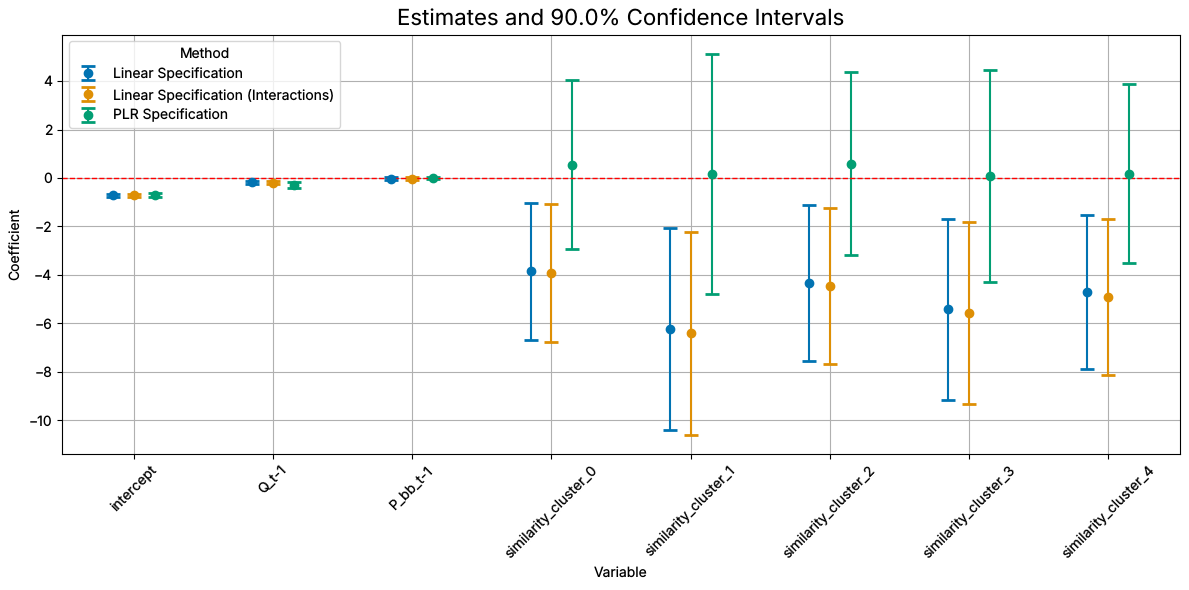

In [49]:
models = cate_summary_df["model"].unique()
variables = cate_summary_df["variable"].unique()
plt.figure(figsize=(12, 6))
bar_width = 0.15
x_positions = np.arange(len(variables))
for i, model in enumerate(models):
    df_model = cate_summary_df[cate_summary_df["model"] == model]
    if not df_model.empty:
        plt.errorbar(
            x_positions + i * bar_width,
            df_model["coef"],
            yerr=[
                df_model["coef"] - df_model["lower"],
                df_model["upper"] - df_model["coef"],
            ],
            fmt="o",
            label=model,
            capsize=5,
            capthick=2,
            ecolor=palette[i % len(palette)],
            color=palette[i % len(palette)],
            zorder=2,
        )
plt.xticks(x_positions + (len(models) - 1) * bar_width / 2, variables, rotation=45)
plt.axhline(0, color="red", linestyle="--", linewidth=1)
plt.title(f"Estimates and {ci_level_name} Confidence Intervals", fontsize=16)
plt.xlabel("Variable")
plt.ylabel("Coefficient")
plt.legend(title="Method")
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, f"cluster_and_level_cate_estimates.png"))
plt.show()

### $R^2$

In [50]:
alpha_x_lin = cate_models_polynomial["Linear Specification"].predict(df_basis)
alpha_x_lin_interactions = cate_models_polynomial[
    "Linear Specification (Interactions)"
].predict(df_basis)
alpha_x_plr = cate_models_polynomial["PLR Specification"].blp_model.predict(df_basis)


print("Linear Specification")
model_lin_emb = sm.OLS(alpha_x_lin, sm.add_constant(df_dynamic[embeddings])).fit()
model_lin_sim = sm.OLS(
    alpha_x_lin, sm.add_constant(df_dynamic[controls_similarities])
).fit()
model_lin_lvl = sm.OLS(alpha_x_lin, sm.add_constant(df_dynamic[lag_1_vars])).fit()

print("Variance explained by embeddings: ", model_lin_emb.rsquared)
print("Variance explained by similarities: ", model_lin_sim.rsquared)
print("Variance explained by lagged variables: ", model_lin_lvl.rsquared)

print("Linear Specification with interactions")
model_lin_interactions_emb = sm.OLS(
    alpha_x_lin_interactions, sm.add_constant(df_dynamic[embeddings])
).fit()
model_lin_interactions_sim = sm.OLS(
    alpha_x_lin_interactions, sm.add_constant(df_dynamic[controls_similarities])
).fit()
model_lin_interactions_lvl = sm.OLS(
    alpha_x_lin_interactions, sm.add_constant(df_dynamic[lag_1_vars])
).fit()
print("Variance explained by embeddings: ", model_lin_interactions_emb.rsquared)
print("Variance explained by similarities: ", model_lin_interactions_sim.rsquared)
print("Variance explained by lagged variables: ", model_lin_interactions_lvl.rsquared)

print("PLR Specification")
model_plr_emb = sm.OLS(alpha_x_plr, sm.add_constant(df_dynamic[embeddings])).fit()
model_plr_sim = sm.OLS(
    alpha_x_plr, sm.add_constant(df_dynamic[controls_similarities])
).fit()
model_plr_lvl = sm.OLS(alpha_x_plr, sm.add_constant(df_dynamic[lag_1_vars])).fit()
print("Variance explained by embeddings: ", model_plr_emb.rsquared)
print("Variance explained by similarities: ", model_plr_sim.rsquared)
print("Variance explained by lagged variables: ", model_plr_lvl.rsquared)

Linear Specification


Variance explained by embeddings:  0.6873849020699656
Variance explained by similarities:  0.5672021169381989
Variance explained by lagged variables:  0.5914686507759348
Linear Specification with interactions


Variance explained by embeddings:  0.6866744803298432
Variance explained by similarities:  0.5647289739930572
Variance explained by lagged variables:  0.5868138955149934
PLR Specification


Variance explained by embeddings:  0.48581954622480905
Variance explained by similarities:  0.2973574462068863
Variance explained by lagged variables:  0.7764052856507732


## $\Chi^2$ Test

In [51]:
# select index with cluster similarity
cluster_treatment_ids = [
    i for i, variable in enumerate(df_basis.columns) if "similarity_cluster" in variable
]
cluster_treatment_ids

[3, 4, 5, 6, 7]

In [52]:
lin_p_val = chi2_test(
    cate_models_polynomial["Linear Specification"], cluster_treatment_ids
)
lin_interactions_p_val = chi2_test(
    cate_models_polynomial["Linear Specification (Interactions)"], cluster_treatment_ids
)
tab_dml_p_val = chi2_test(
    cate_models_polynomial["PLR Specification"], cluster_treatment_ids
)

print(f"Linear Specification p-value: {lin_p_val} (sample size: {len(df_dynamic)})")
print(
    f"Linear Specification (Interactions) p-value: {lin_interactions_p_val} (sample size: {len(df_dynamic)})"
)
print(f"PLR Specification p-value: {tab_dml_p_val} (sample size: {len(df_dynamic)})")

Linear Specification p-value: 0.00116615779167617 (sample size: 38041)
Linear Specification (Interactions) p-value: 0.0006873333246726343 (sample size: 38041)
PLR Specification p-value: 0.011641517931017642 (sample size: 38041)


In [53]:
het_ids = [1, 2, 3, 4, 5, 6, 7]

lin_p_val = chi2_test(cate_models_polynomial["Linear Specification"], het_ids)
lin_interactions_p_val = chi2_test(
    cate_models_polynomial["Linear Specification (Interactions)"], het_ids
)
tab_dml_p_val = chi2_test(cate_models_polynomial["PLR Specification"], het_ids)

print(f"Linear Specification p-value: {lin_p_val} (sample size: {len(df_dynamic)})")
print(
    f"Linear Specification (Interactions) p-value: {lin_interactions_p_val} (sample size: {len(df_dynamic)})"
)
print(f"PLR Specification p-value: {tab_dml_p_val} (sample size: {len(df_dynamic)})")

Linear Specification p-value: 1.2893218537257667e-07 (sample size: 38041)
Linear Specification (Interactions) p-value: 3.921103097770384e-08 (sample size: 38041)
PLR Specification p-value: 3.5305402052765444e-05 (sample size: 38041)


## Sorted Effects

In [54]:
treatment_ids = [0, 1, 2] + cluster_treatment_ids
df_basis_sorted = df_basis.iloc[:, treatment_ids]  # .join(df_dynamic[["ASIN", "date"]])

In [55]:
df_basis_sorted

,intercept,Q_t-1,P_bb_t-1,similarity_cluster_0,similarity_cluster_1,similarity_cluster_2,similarity_cluster_3,similarity_cluster_4
0,1.0,0.305280,0.463601,-0.124667,0.032045,0.153362,-0.011670,-0.111980
1,1.0,0.272505,0.653600,-0.124667,0.032045,0.153362,-0.011670,-0.111980
2,1.0,0.036240,0.687961,-0.124667,0.032045,0.153362,-0.011670,-0.111980
3,1.0,0.025283,0.636881,-0.124667,0.032045,0.153362,-0.011670,-0.111980
4,1.0,-0.051370,0.556816,-0.124667,0.032045,0.153362,-0.011670,-0.111980
...,...,...,...,...,...,...,...,...
38036,1.0,0.009068,0.478593,0.388261,-0.372537,0.020442,0.046374,0.056719
38037,1.0,-0.393270,-0.753352,-0.041433,0.179180,-0.026505,-0.050134,-0.108143
38038,1.0,-0.277916,-0.753352,-0.029876,0.124869,0.024743,-0.034132,-0.118597
38039,1.0,1.267533,-1.535804,0.145326,-0.002473,-0.194913,-0.467553,0.652700


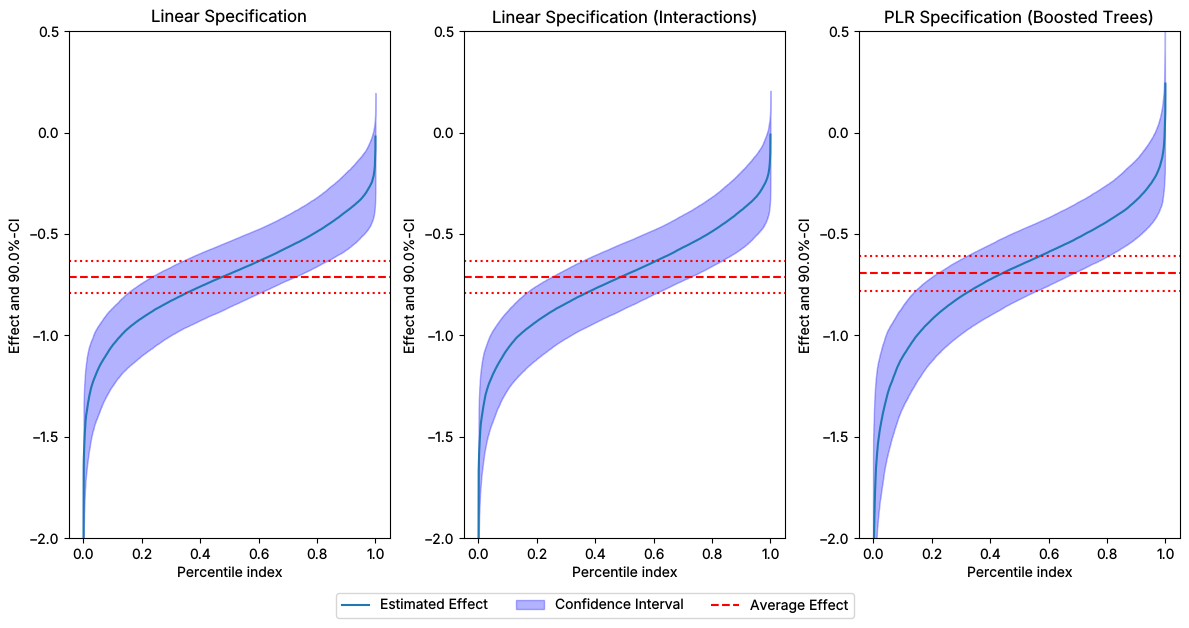

In [56]:
uniform_ci = False

plt.rcParams["figure.figsize"] = (
    15.0,
    7.5,
)  # Adjusted the figure size for side-by-side plots
# Determine the number of models to plot
num_plots = 1
# Create subplots with cate_vars as rows and models as columns
fig, axs = plt.subplots(nrows=num_plots, ncols=3, figsize=(12, 6 * num_plots))
# If there's only one model, axs won't be a list, so wrap it in a list
if num_plots == 1:
    axs = np.array([axs, axs])  # Create a 2-column array


# Linear model
df_lin_ci_pointwise = predict_cate(
    cate_models_polynomial["Linear Specification"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
)
df_lin_ci_pointwise_sorted = df_lin_ci_pointwise.apply(
    lambda x: x.sort_values().values, axis=0
)
df_lin_ci_uniform = predict_cate(
    cate_models_polynomial["Linear Specification"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
    joint=True,
)
df_lin_ci_uniform_sorted = df_lin_ci_uniform.apply(
    lambda x: x.sort_values().values, axis=0
)
lm_intercept = cate_models_polynomial["Linear Specification"].params["intercept"]
lm_intercept_ci = (
    cate_models_polynomial["Linear Specification"].conf_int().loc["intercept"]
)

# Tabular DML model
df_tab_dml_ci_pointwise = predict_cate(
    cate_models_polynomial["Linear Specification (Interactions)"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
)
df_tab_dml_ci_pointwise_sorted = df_tab_dml_ci_pointwise.apply(
    lambda x: x.sort_values().values, axis=0
)
df_tab_dml_ci_joint = predict_cate(
    cate_models_polynomial["Linear Specification (Interactions)"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
    joint=True,
)
df_tab_dml_ci_joint_sorted = df_tab_dml_ci_joint.apply(
    lambda x: x.sort_values().values, axis=0
)

tab_dml_intercept = cate_models_polynomial["Linear Specification"].params["intercept"]
tab_dml_intercept_ci = (
    cate_models_polynomial["Linear Specification"].conf_int().loc["intercept"]
)

# PLR Model
df_deep_dml_ci_pointwise = predict_cate(
    cate_models_polynomial["PLR Specification"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
)
df_deep_dml_ci_pointwise_sorted = df_deep_dml_ci_pointwise.apply(
    lambda x: x.sort_values().values, axis=0
)
df_deep_dml_ci_joint = predict_cate(
    cate_models_polynomial["PLR Specification"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
    joint=True,
)
df_deep_dml_ci_joint_sorted = df_deep_dml_ci_joint.apply(
    lambda x: x.sort_values().values, axis=0
)
deep_dml_intercept = cate_models_polynomial["PLR Specification"].blp_model.params[
    "intercept"
]
deep_dml_intercept_ci = (
    cate_models_polynomial["PLR Specification"].blp_model.conf_int().loc["intercept"]
)

# Calculate the y-axis limits for this row
y_min = min(
    df_lin_ci_pointwise[ci_names[0]].min(),
    df_lin_ci_uniform[ci_names[0]].min(),
    df_tab_dml_ci_pointwise[ci_names[0]].min(),
    df_tab_dml_ci_joint[ci_names[0]].min(),
    df_deep_dml_ci_pointwise[ci_names[0]].min(),
    df_deep_dml_ci_joint[ci_names[0]].min(),
)
y_max = max(
    df_lin_ci_pointwise[ci_names[1]].max(),
    df_lin_ci_uniform[ci_names[1]].max(),
    df_tab_dml_ci_pointwise[ci_names[1]].max(),
    df_tab_dml_ci_joint[ci_names[1]].max(),
    df_deep_dml_ci_pointwise[ci_names[1]].max(),
    df_deep_dml_ci_joint[ci_names[1]].max(),
)

# further adjust y-axis limits
y_min = max(y_min, -2)
y_max = min(y_max, 0.5)
percentiles_idx = np.linspace(0, 1, df_dynamic.shape[0])
percentiles_idx_full = np.linspace(0, 1, df_dynamic.shape[0])
# Plot on the first column
i = 0
ax0 = axs[i, 0]
ax0.plot(
    percentiles_idx_full, df_lin_ci_pointwise_sorted["effect"], label="Estimated Effect"
)
ax0.fill_between(
    percentiles_idx_full,
    df_lin_ci_pointwise_sorted[ci_names[0]],
    df_lin_ci_pointwise_sorted[ci_names[1]],
    color="b",
    alpha=0.3,
    label="Confidence Interval",
)
if uniform_ci:
    ax0.fill_between(
        percentiles_idx_full,
        df_lin_ci_uniform_sorted[ci_names[0]],
        df_lin_ci_uniform_sorted[ci_names[1]],
        color="b",
        alpha=0.1,
        label="Uniform Confidence Interval",
    )
ax0.axhline(y=lm_intercept, color="r", linestyle="--", label="ATE")
ax0.axhline(y=lm_intercept_ci[0], color="r", linestyle="dotted")
ax0.axhline(y=lm_intercept_ci[1], color="r", linestyle="dotted")
ax0.set_title("Linear Specification")
ax0.set_xlabel("Percentile index")
ax0.set_ylabel(f"Effect and {ci_level_name}-CI")
ax0.set_ylim(y_min, y_max)
ax1 = axs[i, 1]
ax1.plot(
    percentiles_idx_full,
    df_tab_dml_ci_pointwise_sorted["effect"],
    label="Estimated Effect",
)
ax1.fill_between(
    percentiles_idx_full,
    df_tab_dml_ci_pointwise_sorted[ci_names[0]],
    df_tab_dml_ci_pointwise_sorted[ci_names[1]],
    color="b",
    alpha=0.3,
    label="Confidence Interval",
)
if uniform_ci:
    ax1.fill_between(
        percentiles_idx_full,
        df_tab_dml_ci_joint_sorted[ci_names[0]],
        df_tab_dml_ci_joint_sorted[ci_names[1]],
        color="b",
        alpha=0.1,
        label="Uniform Confidence Interval",
    )
ax1.axhline(y=tab_dml_intercept, color="r", linestyle="--", label="Average Effect")
ax1.axhline(y=tab_dml_intercept_ci[0], color="r", linestyle="dotted")
ax1.axhline(y=tab_dml_intercept_ci[1], color="r", linestyle="dotted")
ax1.set_title("Linear Specification (Interactions)")
ax1.set_xlabel("Percentile index")
ax1.set_ylabel(f"Effect and {ci_level_name}-CI")
ax1.set_ylim(y_min, y_max)

ax2 = axs[i, 2]
ax2.plot(
    percentiles_idx_full,
    df_deep_dml_ci_pointwise_sorted["effect"],
    label="Estimated Effect",
)
ax2.fill_between(
    percentiles_idx_full,
    df_deep_dml_ci_pointwise_sorted[ci_names[0]],
    df_deep_dml_ci_pointwise_sorted[ci_names[1]],
    color="b",
    alpha=0.3,
    label="Confidence Interval",
)
if uniform_ci:
    ax2.fill_between(
        percentiles_idx_full,
        df_deep_dml_ci_joint_sorted[ci_names[0]],
        df_deep_dml_ci_joint_sorted[ci_names[1]],
        color="b",
        alpha=0.1,
        label="Uniform Confidence Interval",
    )
ax2.axhline(y=deep_dml_intercept, color="r", linestyle="--", label="Average Effect")
ax2.axhline(y=deep_dml_intercept_ci[0], color="r", linestyle="dotted")
ax2.axhline(y=deep_dml_intercept_ci[1], color="r", linestyle="dotted")

ax2.set_title("PLR Specification (Boosted Trees)")
ax2.set_xlabel("Percentile index")
ax2.set_ylabel(f"Effect and {ci_level_name}-CI")
ax2.set_ylim(y_min, y_max)

# Create a single legend for all plots and place it at the lower center
handles, labels = axs[
    -1, 1 
].get_legend_handles_labels()  # Collect handles and labels from the last subplot
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, -0.05), ncol=4)
# Adjust layout to make space for the legend
plt.tight_layout(rect=[0, 0.0, 1, 1])  # Leave space at the bottom for the legend

# Save the figure with tight bounding box to include the legend
plt.savefig(os.path.join(output_dir, "cluster_sorted_effects.png"), bbox_inches="tight")
plt.show()

In [57]:
quantiles = np.arange(start=0.01, stop=1, step=0.01)
m = len(quantiles)
pes = df_tab_dml_ci_pointwise["effect"]
spes = df_tab_dml_ci_pointwise["effect"].quantile(quantiles).values
spes

array([-1.41076874, -1.32219188, -1.26284411, -1.22355298, -1.18970447,
       -1.16044542, -1.13437161, -1.11105549, -1.08573796, -1.06566377,
       -1.04671445, -1.02917231, -1.01159299, -0.99842641, -0.98530076,
       -0.97341073, -0.96199669, -0.95099225, -0.93996313, -0.92999342,
       -0.91954527, -0.91004384, -0.90048374, -0.89078501, -0.88228881,
       -0.87368787, -0.86463978, -0.85727739, -0.84944656, -0.8416839 ,
       -0.83419869, -0.82613169, -0.81868495, -0.81089591, -0.80392986,
       -0.79670475, -0.7896339 , -0.78286052, -0.77575503, -0.76845025,
       -0.76163155, -0.75554099, -0.74922714, -0.74227888, -0.73551795,
       -0.72939541, -0.72260011, -0.71579894, -0.70956867, -0.70341209,
       -0.69661832, -0.69026279, -0.68405798, -0.6779921 , -0.67131338,
       -0.66468511, -0.657904  , -0.65159789, -0.64492393, -0.63830854,
       -0.63076562, -0.62393629, -0.61725293, -0.61042097, -0.60387217,
       -0.59657886, -0.58949247, -0.58101021, -0.57368661, -0.56

# Sensitivity Analysis

Sensitivity analysis for ATE with PLM model.

In [58]:
plr_obj.sensitivity_analysis(
    cf_y=0.03,
    cf_d=0.03,
    rho=1.0,
    level=0.9,
    null_hypothesis=0.0
)
print(plr_obj.sensitivity_summary)

================== Sensitivity Analysis ==================

------------------ Scenario          ------------------
Significance Level: level=0.9
Sensitivity parameters: cf_y=0.03; cf_d=0.03, rho=1.0

------------------ Bounds with CI    ------------------
        CI lower  theta lower     theta  theta upper  CI upper
P_bb_t -0.891866     -0.83473 -0.700539    -0.566349 -0.505165

------------------ Robustness Values ------------------
        H_0     RV (%)    RVa (%)
P_bb_t  0.0  14.687702  13.285516


In [59]:
sigma_l = tab_dml_obj_embeddings_add_controls.sensitivity_elements["sigma2"]
sigma_s = tab_dml_obj_embeddings.sensitivity_elements["sigma2"]

nu_l = tab_dml_obj_embeddings_add_controls.sensitivity_elements["nu2"]
nu_s = tab_dml_obj_embeddings.sensitivity_elements["nu2"]

delta_theta = tab_dml_obj_embeddings_add_controls.coef - tab_dml_obj_embeddings.coef

rho_hat = np.abs(delta_theta) / (np.sqrt(sigma_s - sigma_l) * np.sqrt(nu_l - nu_s)).squeeze()

print(f"Implied rho: {rho_hat}")

Implied rho: [0.0843615]


In [60]:
r2_scores_l = tab_dml_obj_embeddings_add_controls.evaluate_learners(metric=r2)
print(
    f"R2 Outcome: {r2_scores_l['ml_l'][0, 0]} R2 Treatment: {r2_scores_l['ml_m'][0, 0]}\n"
)

r2_y_l = r2_scores_l["ml_l"][0, 0]
r2_d_l = r2_scores_l["ml_m"][0, 0]


r2_scores_s = tab_dml_obj_embeddings.evaluate_learners(metric=r2)
print(
    f"R2 Outcome: {r2_scores_s['ml_l'][0, 0]} R2 Treatment: {r2_scores_s['ml_m'][0, 0]}\n"
)

r2_y_s = r2_scores_s["ml_l"][0, 0]
r2_d_s = r2_scores_s["ml_m"][0, 0]

R2 Outcome: 0.895296367162455 R2 Treatment: 0.9762424430068902

R2 Outcome: 0.8692023018541428 R2 Treatment: 0.9745845500525019



In [61]:
partial_r2_y = (r2_y_l - r2_y_s) / (1 - r2_y_s)
partial_r2_d = (r2_d_l - r2_d_s) / (1 - r2_d_s)

print(f"Partial R2 Outcome: {partial_r2_y}")
print(f"Partial R2 Treatment: {partial_r2_d}")

Partial R2 Outcome: 0.19949942298842088
Partial R2 Treatment: 0.06523169795589405


In [62]:
# NEW CHECK

K = rho_hat * np.sqrt(partial_r2_y * partial_r2_d / (1 - partial_r2_d))
scaled_implied_RV = (-K**2 + K*np.sqrt(K**2 + 4)) / 2

print(scaled_implied_RV.round(4))

[0.0099]


In [63]:
# Check

np.sqrt(scaled_implied_RV * scaled_implied_RV / (1 - scaled_implied_RV))

array([0.00995388])

In [64]:
sensitivity_res = dict()

rho_vec = [1.0, 0.5, 0.2]
scenarios = [(0.01, 0.01), (0.025, 0.025), (0.05, 0.05)]

theta_lower = []
theta_upper = []
ci_lower = []   
ci_upper = []
R2_y = []
R2_d = []
rho_list = []

for rho in rho_vec:
    for cf_y, cf_d in scenarios:
        plr_obj.sensitivity_analysis(
            cf_y=cf_y,
            cf_d=cf_d,
            rho=rho,
            level=confidence_level,
            null_hypothesis=0.0
        )
        theta_lower.append(plr_obj.sensitivity_params["theta"]["lower"][0])
        theta_upper.append(plr_obj.sensitivity_params["theta"]["upper"][0])
        ci_lower.append(plr_obj.sensitivity_params["ci"]["lower"][0])
        ci_upper.append(plr_obj.sensitivity_params["ci"]["upper"][0])
        R2_y.append(cf_y)
        R2_d.append(cf_d)
        rho_list.append(rho)


In [65]:
df_sensitivity = pd.DataFrame({
    "theta": plr_obj.coef[0],
    "theta_lower": theta_lower,
    "theta_upper": theta_upper,
    "ci_lower": ci_lower,
    "ci_upper": ci_upper,
    "R2_y": R2_y,
    "R2_d": R2_d,
    "rho": rho_list,
})
df_sensitivity.head()

,theta,theta_lower,theta_upper,ci_lower,ci_upper,R2_y,R2_d,rho
0,-0.700539,-0.744815,-0.656263,-0.803134,-0.596605,0.010,0.010,1.0
1,-0.700539,-0.812078,-0.589001,-0.869494,-0.528217,0.025,0.025,1.0
2,-0.700539,-0.926532,-0.474547,-0.982656,-0.411646,0.050,0.050,1.0
3,-0.700539,-0.722677,-0.678401,-0.781315,-0.619094,0.010,0.010,0.5
4,-0.700539,-0.756308,-0.644770,-0.814466,-0.584926,0.025,0.025,0.5


In [66]:
scenario_names = ["mild", "medium", "strong"]

latex_args = {
    "index": False,
    "float_format": "%.3f",
    "column_format": "lcccccc",
    "escape": False,  # Allow LaTeX in column names
}

ci_lower_label = f"$[ {{{100*(1-confidence_level):.1f}}}\\% $"
ci_upper_label = f"${{{100*(confidence_level):.1f}}}\\% ]$"

for rho_val in rho_vec:
    df_rho = df_sensitivity[df_sensitivity["rho"] == rho_val].copy()
    # Add scenario column with names
    df_rho["Scenario ($R^2_Y$, $R^2_D$)"] = [
        f"{name} $({str(r2y).lstrip('0')}, {str(r2d).lstrip('0')})$"
        for name, r2y, r2d in zip(scenario_names, df_rho["R2_y"], df_rho["R2_d"])
    ]
    # Rename columns for LaTeX
    df_rho = df_rho.rename(
        columns={
            "theta": r"$\theta$",
            "theta_lower": r"$\theta_-$",
            "theta_upper": r"$\theta_+$",
            "ci_lower": ci_lower_label,
            "ci_upper": ci_upper_label,
        }
    )
    # Reorder columns as requested
    df_rho = df_rho[
        [
            "Scenario ($R^2_Y$, $R^2_D$)",
            ci_lower_label,
            r"$\theta_-$",
            r"$\theta$",
            r"$\theta_+$",
            ci_upper_label,
        ]
    ]
    caption = (
        f"Sensitivity analysis for $\\rho={rho_val}$: "
    )
    latex_str = df_rho.to_latex(
        caption=caption,
        label=f"tab:sensitivity_rho_{str(rho_val).replace('.', '')}",
        **latex_args,
    )
    # Insert \hline\hline after \begin{tabular} and replace \toprule/\bottomrule
    latex_str = latex_str.replace("\\toprule", "\\hline\\hline")
    latex_str = latex_str.replace("\\midrule", "\\midrule")
    latex_str = latex_str.replace("\\bottomrule", "\\hline\\hline")
    latex_str = latex_str.replace("\\begin{table}", "\\begin{table}[h]\n\\centering")
    print(latex_str)

\begin{table}[h]
\centering
\caption{Sensitivity analysis for $\rho=1.0$: }
\label{tab:sensitivity_rho_10}
\begin{tabular}{lcccccc}
\hline\hline
Scenario ($R^2_Y$, $R^2_D$) & $[ {10.0}\% $ & $\theta_-$ & $\theta$ & $\theta_+$ & ${90.0}\% ]$ \\
\midrule
mild $(.01, .01)$ & -0.803 & -0.745 & -0.701 & -0.656 & -0.597 \\
medium $(.025, .025)$ & -0.869 & -0.812 & -0.701 & -0.589 & -0.528 \\
strong $(.05, .05)$ & -0.983 & -0.927 & -0.701 & -0.475 & -0.412 \\
\hline\hline
\end{tabular}
\end{table}

\begin{table}[h]
\centering
\caption{Sensitivity analysis for $\rho=0.5$: }
\label{tab:sensitivity_rho_05}
\begin{tabular}{lcccccc}
\hline\hline
Scenario ($R^2_Y$, $R^2_D$) & $[ {10.0}\% $ & $\theta_-$ & $\theta$ & $\theta_+$ & ${90.0}\% ]$ \\
\midrule
mild $(.01, .01)$ & -0.781 & -0.723 & -0.701 & -0.678 & -0.619 \\
medium $(.025, .025)$ & -0.814 & -0.756 & -0.701 & -0.645 & -0.585 \\
strong $(.05, .05)$ & -0.871 & -0.814 & -0.701 & -0.588 & -0.527 \\
\hline\hline
\end{tabular}
\end{table}

\begin

# Export of Key Results

Collects the main estimates of this notebook in `output_dir` for the comparison across embeddings (`04_evaluation_gemma_comparison.ipynb`).

In [67]:
import json

key_results = {
    "embedding_source": embedding_source,
    "modality": modality if embedding_source != "finetuned" else "txtimg",
    "emb_dim": n_embeddings,
    "dataset": dataframe_name,
    "n_obs": int(len(df_dynamic)),
    "n_products": int(df_dynamic["ASIN"].nunique()),
}

# Linear models (ATE)
ci_linear_interactions["model"] = "Linear interactions"
df_linear = pd.concat([df_base, ci_linear_interactions], ignore_index=True)
df_linear.to_csv(os.path.join(output_dir, "linear_ate_estimates.csv"), index=False)

# PLR models (ATE) and learner R^2
plr_objects = {
    "plr_embeddings": tab_dml_obj_embeddings,
    "plr_add_controls": tab_dml_obj_add_controls,
    "plr_embeddings_add_controls": tab_dml_obj_embeddings_add_controls,
    "plr_sim_add_controls": tab_dml_obj_sim_add_controls,
    "plr_pca_add_controls": tab_dml_obj_pca_add_controls,
}
df_plr = df_averages.copy()
for model_name, obj in plr_objects.items():
    r2_scores = obj.evaluate_learners(metric=r2)
    df_plr.loc[df_plr["model"] == model_name, "std_err"] = obj.se[0]
    df_plr.loc[df_plr["model"] == model_name, "r2_outcome"] = r2_scores["ml_l"][0, 0]
    df_plr.loc[df_plr["model"] == model_name, "r2_treatment"] = r2_scores["ml_m"][0, 0]
df_plr.to_csv(os.path.join(output_dir, "plr_ate_estimates.csv"), index=False)
df_plr

,lower,upper,coef,model,std_err,r2_outcome,r2_treatment
0,-0.724660,-0.580114,-0.652387,plr_embeddings,0.043939,0.869202,0.974585
1,-0.757775,-0.622714,-0.690244,plr_add_controls,0.041056,0.899101,0.977486
2,-0.776224,-0.624855,-0.700539,plr_embeddings_add_controls,0.046013,0.895296,0.976242
3,-0.749068,-0.619653,-0.684361,plr_sim_add_controls,0.039339,0.899834,0.977048
4,-0.756658,-0.622137,-0.689398,plr_pca_add_controls,0.040892,0.899506,0.977014


In [68]:
# GATEs by most similar cluster
df_gates = gates_0_summ.copy()
group_sizes = groups.groupby(0).size()
group_sizes.index = "Group_" + group_sizes.index.astype(str)  # labels used by DoubleMLPLR.gate()
df_gates["n_obs"] = group_sizes.reindex(df_gates.index).values
assert df_gates["n_obs"].notna().all()
df_gates.to_csv(os.path.join(output_dir, "gate_estimates.csv"))

# CATE (best linear predictor) coefficients
cate_summary_df.to_csv(os.path.join(output_dir, "cate_estimates.csv"), index=False)

# Chi^2 tests
chi2_rows = []
for model_name, model in cate_models_polynomial.items():
    chi2_rows.append(
        {
            "model": model_name,
            "p_value_clusters": chi2_test(model, cluster_treatment_ids),
            "p_value_heterogeneity": chi2_test(model, het_ids),
        }
    )
df_chi2 = pd.DataFrame(chi2_rows)
df_chi2.to_csv(os.path.join(output_dir, "chi2_tests.csv"), index=False)

# Variance of the CATE explained by embeddings, similarities and lagged variables
df_var_explained = pd.DataFrame(
    {
        "Linear Specification": [model_lin_emb.rsquared, model_lin_sim.rsquared, model_lin_lvl.rsquared],
        "Linear Specification (Interactions)": [
            model_lin_interactions_emb.rsquared,
            model_lin_interactions_sim.rsquared,
            model_lin_interactions_lvl.rsquared,
        ],
        "PLR Specification": [model_plr_emb.rsquared, model_plr_sim.rsquared, model_plr_lvl.rsquared],
    },
    index=["embeddings", "similarities", "lagged variables"],
)
df_var_explained.to_csv(os.path.join(output_dir, "cate_variance_explained.csv"))
df_chi2

,model,p_value_clusters,p_value_heterogeneity
0,Linear Specification,0.001166,1.289322e-07
1,Linear Specification (Interactions),0.000687,3.921103e-08
2,PLR Specification,0.011642,3.530540e-05


In [69]:
# Per-observation CATEs (as in ../output/04_evaluation/sorted_effects.csv)
df_sorted_effects = df_dynamic[["ASIN", "date"]].copy()
df_sorted_effects["SortEff_lin"] = df_lin_ci_pointwise["effect"].values
df_sorted_effects["SortEff_tab_dml"] = df_tab_dml_ci_pointwise["effect"].values
df_sorted_effects["SortEff_deep_dml"] = df_deep_dml_ci_pointwise["effect"].values
df_sorted_effects.to_csv(os.path.join(output_dir, "sorted_effects.csv"), index=False)

# Sensitivity analysis
df_sensitivity.to_csv(os.path.join(output_dir, "sensitivity_analysis.csv"), index=False)
plr_obj.sensitivity_analysis(cf_y=0.03, cf_d=0.03, rho=1.0, level=0.9, null_hypothesis=0.0)
key_results["sensitivity"] = {
    "theta": float(plr_obj.coef[0]),
    "theta_lower_cf003": float(plr_obj.sensitivity_params["theta"]["lower"][0]),
    "theta_upper_cf003": float(plr_obj.sensitivity_params["theta"]["upper"][0]),
    "ci_lower_cf003": float(plr_obj.sensitivity_params["ci"]["lower"][0]),
    "ci_upper_cf003": float(plr_obj.sensitivity_params["ci"]["upper"][0]),
    "rv": float(plr_obj.sensitivity_params["rv"][0]),
    "rva": float(plr_obj.sensitivity_params["rva"][0]),
    "implied_rho": float(np.squeeze(rho_hat)),
    "partial_r2_outcome": float(partial_r2_y),
    "partial_r2_treatment": float(partial_r2_d),
    "scaled_implied_rv": float(np.squeeze(scaled_implied_RV)),
}
key_results["sorted_effects_quantiles"] = {
    col: df_sorted_effects[col].quantile([0.05, 0.25, 0.5, 0.75, 0.95]).round(6).tolist()
    for col in ["SortEff_lin", "SortEff_tab_dml", "SortEff_deep_dml"]
}
with open(os.path.join(output_dir, "key_results.json"), "w") as f:
    json.dump(key_results, f, indent=2)
print(json.dumps(key_results, indent=2))

{
  "embedding_source": "embeddinggemma2",
  "modality": "txtimg",
  "emb_dim": 256,
  "dataset": "dataset_gemma_txtimg_dim256",
  "n_obs": 38041,
  "n_products": 3708,
  "sensitivity": {
    "theta": -0.7005393852580923,
    "theta_lower_cf003": -0.8347297574096405,
    "theta_upper_cf003": -0.5663490131065442,
    "ci_lower_cf003": -0.8918657239427272,
    "ci_upper_cf003": -0.5051651822487759,
    "rv": 0.14687702370247352,
    "rva": 0.13285516011612325,
    "implied_rho": 0.08436150187272491,
    "partial_r2_outcome": 0.19949942298842088,
    "partial_r2_treatment": 0.06523169795589405,
    "scaled_implied_rv": 0.009904465162968782
  },
  "sorted_effects_quantiles": {
    "SortEff_lin": [
      -1.167625,
      -0.868216,
      -0.696454,
      -0.528835,
      -0.328311
    ],
    "SortEff_tab_dml": [
      -1.189704,
      -0.882289,
      -0.703412,
      -0.529142,
      -0.318408
    ],
    "SortEff_deep_dml": [
      -1.279554,
      -0.859527,
      -0.654035,
      -0.4806